# PYTORCH MASTERY — NOTEBOOK 4
## Chapters 16–20: nn.Module → Layers → Activation Functions → Loss Functions → Optimizers

Continuing directly from Notebook 3. This is where you build your first genuine neural network components.


### PYTORCH MASTERY PROGRESS
Current Chapter: 20 | Current Level: Neural Network Fundamentals

- [x] Chapters 1–15 *(Notebooks 1–3)*
- [x] nn.Module
- [x] Layers
- [x] Activation Functions
- [x] Loss Functions
- [x] Optimizers


---
# CHAPTER 16 — nn.MODULE

## 1. Concept
`nn.Module` is the base class for **every** neural network component in PyTorch — from a single layer to an entire complex architecture. It provides the infrastructure that makes a network's parameters discoverable, movable between devices, saveable/loadable, and composable into larger networks — all through a small, consistent set of conventions you'll follow in essentially every model you ever write.

## 2. The Minimal `nn.Module` Pattern


In [ ]:
import torch
import torch.nn as nn

class SimpleNetwork(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()   # MANDATORY -- initializes nn.Module's internal bookkeeping
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.activation = nn.ReLU()
        self.layer2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        return x


model = SimpleNetwork(input_dim=10, hidden_dim=32, output_dim=2)
print(model)

sample_input = torch.randn(4, 10)   # a BATCH of 4 samples, 10 features each
output = model(sample_input)         # calling model(x) invokes model.forward(x) -- NEVER call .forward() directly
print("\nOutput shape:", output.shape, " (batch=4, output_dim=2)")


SimpleNetwork(
  (layer1): Linear(in_features=10, out_features=32, bias=True)
  (activation): ReLU()
  (layer2): Linear(in_features=32, out_features=2, bias=True)
)

Output shape: torch.Size([4, 2])  (batch=4, output_dim=2)


### Line-by-Line Explanation
- `class SimpleNetwork(nn.Module):` — inheriting from `nn.Module` is what grants your class all of its infrastructure: parameter tracking, `.to(device)`, `.train()`/`.eval()` mode switching, `.state_dict()`, and more — none of this "just works" without this inheritance.
- `super().__init__()` — **mandatory**, and must be the first line of `__init__`. This calls `nn.Module`'s own constructor, which sets up the internal dictionaries (`_parameters`, `_modules`, `_buffers`) that everything else in this chapter depends on. **Forgetting this line is a genuinely common mistake** that produces a confusing error later (often when trying to access `.parameters()`), not at the point of the actual omission.
- `self.layer1 = nn.Linear(...)` — assigning an `nn.Module` instance (like `nn.Linear`) as an attribute of another `nn.Module` **automatically registers it as a submodule** — this is a special behavior implemented via `nn.Module.__setattr__`, not ordinary Python attribute assignment; it's precisely what makes `model.parameters()` (below) able to automatically discover every parameter in `layer1` and `layer2` without you manually listing them.
- `def forward(self, x):` — defines the model's actual forward computation; this is the **one method every `nn.Module` subclass must implement**.
- `model(sample_input)` — calling the model instance **directly** (not `model.forward(sample_input)`) is the correct, idiomatic way to run a forward pass — `nn.Module.__call__` does important additional work beyond just invoking `forward()` (running registered hooks, among other things — advanced usage beyond this chapter's scope), so calling `.forward()` directly can silently skip that machinery.

## 3. Parameter Discovery — `parameters()`, `named_parameters()`, `state_dict()`


In [ ]:
print("=== model.parameters() -- an iterator over every trainable tensor ===")
total_params = 0
for p in model.parameters():
    total_params += p.numel()
print("Total trainable parameters:", total_params)

print("\n=== model.named_parameters() -- SAME thing, but with each parameter's NAME ===")
for name, p in model.named_parameters():
    print(f"  {name:<20} shape={tuple(p.shape)}  requires_grad={p.requires_grad}")

print("\n=== model.state_dict() -- an ORDERED DICT of every parameter/buffer, keyed by name ===")
state = model.state_dict()
print("Keys:", list(state.keys()))


=== model.parameters() -- an iterator over every trainable tensor ===
Total trainable parameters: 418

=== model.named_parameters() -- SAME thing, but with each parameter's NAME ===
  layer1.weight        shape=(32, 10)  requires_grad=True
  layer1.bias          shape=(32,)  requires_grad=True
  layer2.weight        shape=(2, 32)  requires_grad=True
  layer2.bias          shape=(2,)  requires_grad=True

=== model.state_dict() -- an ORDERED DICT of every parameter/buffer, keyed by name ===
Keys: ['layer1.weight', 'layer1.bias', 'layer2.weight', 'layer2.bias']


### Line-by-Line Explanation
- `model.parameters()` — returns a **generator** over every `nn.Parameter` (a special tensor subclass, automatically `requires_grad=True`) registered anywhere in the module tree, including submodules — this is exactly what you pass to an optimizer (Chapter 20): `torch.optim.Adam(model.parameters())`.
- `model.named_parameters()` — the same iteration, but yielding `(name, parameter)` pairs — the names (`layer1.weight`, `layer1.bias`, `layer2.weight`, `layer2.bias`) directly reflect the attribute structure you defined in `__init__`, which is exactly why consistent, meaningful attribute naming matters for debugging and interpretability later.
- `model.state_dict()` — the standard tool for **saving/loading** a model (Chapter 70) — an `OrderedDict` mapping every parameter (and buffer, like BatchNorm's running statistics) name to its current tensor value, completely independent of the model's class definition/code — this is precisely why loading a `state_dict` requires you to already have an identically-structured model instantiated first (the state_dict alone doesn't reconstruct the architecture, only the learned values).

## 4. `nn.Sequential` — a Convenience Container for Simple, Linear Stacks


In [ ]:
# For a PURELY sequential (no branching, no custom forward logic) architecture,
# nn.Sequential avoids writing an explicit forward() method at all
sequential_model = nn.Sequential(
    nn.Linear(10, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 2),
)
print(sequential_model)

output2 = sequential_model(torch.randn(4, 10))
print("\nOutput shape:", output2.shape)
print("\nnn.Sequential is STILL an nn.Module -- .parameters(), .state_dict(), .to(device) all work identically.")


Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=2, bias=True)
)

Output shape: torch.Size([4, 2])

nn.Sequential is STILL an nn.Module -- .parameters(), .state_dict(), .to(device) all work identically.


### When to Use `nn.Sequential` vs. a Custom Class
- **`nn.Sequential`**: genuinely simple, single-path architectures with no branching, no skip connections, no custom logic (like conditionally applying a layer) — trades flexibility for brevity.
- **Custom `nn.Module` subclass**: anything with branching (multiple inputs merging, Chapter 68's multi-task models), skip connections (ResNet-style, Chapter 39), or any forward-pass logic beyond a straight sequential chain — which describes the **majority** of real architectures beyond the simplest baselines.

### Buffers — the Other Kind of Persistent State


In [ ]:
class ModelWithBuffer(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(10, 5)
        # register_buffer: persistent state that IS saved/loaded with the model,
        # but is NOT a trainable parameter (no gradient, never updated by the optimizer)
        self.register_buffer("running_mean", torch.zeros(10))

    def forward(self, x):
        return self.linear(x - self.running_mean)


buffer_model = ModelWithBuffer()
print("Parameters (trainable):", [name for name, _ in buffer_model.named_parameters()])
print("Buffers (persistent, non-trainable):", [name for name, _ in buffer_model.named_buffers()])
print("\nBoth appear in state_dict():", list(buffer_model.state_dict().keys()))


Parameters (trainable): ['linear.weight', 'linear.bias']
Buffers (persistent, non-trainable): ['running_mean']

Both appear in state_dict(): ['running_mean', 'linear.weight', 'linear.bias']


### Why Buffers Exist — the Canonical Example: BatchNorm
`register_buffer()` is exactly how `nn.BatchNorm2d` (Chapter 17, 31) stores its running mean/variance statistics — these values genuinely need to persist across training and be saved/loaded with the model (getting them wrong at inference time would break normalization), but they're computed via a running average during training, **not** learned via gradient descent — so they must never appear in `model.parameters()` (which the optimizer updates), yet they must appear in `state_dict()` (for correct saving/loading). This is precisely the distinction `register_buffer()` exists to express.

### Common Mistakes
- Forgetting `super().__init__()` — produces a confusing error only when you later try to use `.parameters()` or similar, not immediately at the point of the actual mistake.
- Calling `model.forward(x)` directly instead of `model(x)` — usually appears to work identically for simple models, but silently skips PyTorch's internal hook machinery, which matters for some advanced use cases (and is simply not the idiomatic, expected pattern).
- Defining a layer inside `forward()` instead of `__init__()` (e.g., `self.layer = nn.Linear(...)` written inside `forward`) — creates a **brand new**, randomly-initialized layer on every single forward call, meaning it never actually trains (its weights are discarded and recreated every time) — a genuinely damaging, sometimes subtle bug.
- Using a plain Python attribute (not `register_buffer`) for non-trainable persistent state — it won't be saved/loaded with `state_dict()`, and won't move automatically with `.to(device)`.

### Interview Insight
**Q: Why must every layer be assigned as an attribute in `__init__`, never created inside `forward()`?**
A: Assigning an `nn.Module` (like `nn.Linear`) as an attribute inside `__init__` triggers `nn.Module`'s special `__setattr__` behavior, registering it as a submodule whose parameters become part of the parent module's `.parameters()` — this is what the optimizer updates during training, and what `.state_dict()` saves. If a layer is instead created inside `forward()`, it's a brand-new object with freshly (randomly) initialized weights on every single call — it's never registered as part of the model's tracked parameters, the optimizer never touches it, and any "learning" that appears to happen is illusory, since the layer is discarded and recreated identically (freshly random) on the very next forward pass.

### Exercise
1. Build a 3-layer `nn.Module` subclass with `input_dim=20, hidden1=64, hidden2=32, output_dim=3`, and verify its total parameter count matches your hand-calculation (`(20*64+64) + (64*32+32) + (32*3+3)`).
2. Print `named_parameters()` for your model and confirm the names match the attribute names you chose.

### Quiz (Chapter 16)
1. What does `super().__init__()` actually set up, and why must it be called first?
2. Why does assigning `self.layer = nn.Linear(...)` in `__init__` "register" it, when assigning a plain Python object wouldn't do anything special?
3. What's the difference between a parameter and a buffer, and give the canonical example of when a buffer is needed?
4. Why should you call `model(x)` rather than `model.forward(x)`?


---
# CHAPTER 17 — LAYERS

## 1. Concept
This chapter surveys the core layer types you'll use constantly — each with a specific purpose, expected input/output shape, and set of common mistakes.

## 2. `nn.Linear` — the Fully-Connected Layer


In [ ]:
import torch
import torch.nn as nn

linear = nn.Linear(in_features=10, out_features=5)

x = torch.randn(32, 10)   # (batch, in_features)
y = linear(x)
print("Input shape:", x.shape, " Output shape:", y.shape)
print("\nWeight shape:", linear.weight.shape, " (out_features, in_features) -- NOTE the order!")
print("Bias shape:", linear.bias.shape)
print("\nComputation: y = x @ weight.T + bias")


Input shape: torch.Size([32, 10])  Output shape: torch.Size([32, 5])

Weight shape: torch.Size([5, 10])  (out_features, in_features) -- NOTE the order!
Bias shape: torch.Size([5])

Computation: y = x @ weight.T + bias


### Parameter Explanation
- `in_features`/`out_features` — the layer transforms the **last** dimension of its input from `in_features` to `out_features`; every other leading dimension (batch, sequence length, etc.) is preserved untouched — `nn.Linear` genuinely works on inputs of any number of leading dimensions, not just strictly 2D `(batch, features)`.
- `linear.weight.shape` is `(out_features, in_features)` — note this is the **transpose** of what you might intuitively expect from the `y = xW + b` formula; PyTorch internally computes `y = x @ weight.T + bias`, storing weight in this transposed layout for computational efficiency reasons. This detail matters when manually inspecting or initializing weights (Chapter 30).
- `bias=True` is the default; `nn.Linear(10, 5, bias=False)` omits the bias term entirely — occasionally done when a layer is immediately followed by BatchNorm (which has its own learnable shift, making an additional bias redundant).

## 3. `nn.Conv2d` — Preview (Full Treatment in Chapter 35)


In [ ]:
conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)

image_batch = torch.randn(8, 3, 32, 32)   # (batch, channels, height, width) -- e.g., CIFAR-10-sized images
feature_maps = conv(image_batch)
print("Input shape:", image_batch.shape)
print("Output shape:", feature_maps.shape, " (channels changed 3->16, spatial size PRESERVED due to padding=1)")


Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 16, 32, 32])  (channels changed 3->16, spatial size PRESERVED due to padding=1)


*(Full mathematical treatment of convolution — kernels, stride, padding, receptive fields — is Chapter 35's dedicated focus; this is a preview showing the shape mechanics.)*

## 4. `nn.Dropout` — Regularization via Random Deactivation


In [ ]:
dropout = nn.Dropout(p=0.5)   # p = probability of ZEROING each element

x = torch.ones(1, 10)

dropout.train()   # dropout is ACTIVE during training
print("Training mode (some values randomly zeroed, survivors SCALED UP):\n", dropout(x))

dropout.eval()   # dropout is a NO-OP during evaluation
print("\nEval mode (dropout does NOTHING -- input passes through unchanged):\n", dropout(x))


Training mode (some values randomly zeroed, survivors SCALED UP):
 tensor([[0., 0., 0., 0., 0., 2., 2., 0., 2., 2.]])

Eval mode (dropout does NOTHING -- input passes through unchanged):
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


### Line-by-Line Explanation — Why Surviving Values Are Scaled Up
During training, `nn.Dropout(p=0.5)` randomly zeros ~50% of elements **and** scales the surviving elements by `1/(1-p) = 2x` — this is called **inverse dropout scaling**, and it exists so that the *expected* sum/magnitude of the layer's output stays consistent whether dropout is active or not, meaning you don't need any special rescaling logic at evaluation time — `dropout.eval()` can simply disable dropout entirely (pass-through), because training already compensated for the scaling. This is exactly why `model.eval()` (Chapter 23) matters so much: forgetting to call it means dropout stays active during evaluation, injecting unwanted randomness into what should be deterministic predictions.

## 5. `nn.BatchNorm1d` / `nn.LayerNorm` — Normalizing Activations


In [ ]:
batch_norm = nn.BatchNorm1d(num_features=10)
layer_norm = nn.LayerNorm(normalized_shape=10)

x = torch.randn(32, 10) * 5 + 3   # deliberately shifted/scaled, to see normalization's effect

bn_output = batch_norm(x)
ln_output = layer_norm(x)

print("Input mean/std (roughly):", x.mean().item(), x.std().item())
print("\nBatchNorm output -- normalized ACROSS THE BATCH, per feature:")
print("  per-feature mean (should be ~0):", bn_output.mean(dim=0)[:3])
print("\nLayerNorm output -- normalized ACROSS FEATURES, per SAMPLE:")
print("  per-sample mean (should be ~0):", ln_output.mean(dim=1)[:3])


Input mean/std (roughly): 3.348911762237549 4.971729755401611

BatchNorm output -- normalized ACROSS THE BATCH, per feature:
  per-feature mean (should be ~0): tensor([8.1956e-08, 1.4901e-08, 0.0000e+00], grad_fn=<SliceBackward0>)

LayerNorm output -- normalized ACROSS FEATURES, per SAMPLE:
  per-sample mean (should be ~0): tensor([ 1.1921e-08,  2.9802e-08, -5.9605e-09], grad_fn=<SliceBackward0>)


### BatchNorm vs. LayerNorm — the Critical Conceptual Difference
- **BatchNorm** normalizes each **feature** using statistics computed **across the batch dimension** — meaning its behavior depends on what other samples happen to be in the same batch, and it requires tracking running statistics (buffers, Chapter 16) for use at inference time when a "batch" might be a single sample. Standard in CNNs (Chapter 35).
- **LayerNorm** normalizes each **sample** using statistics computed **across its own features** — completely independent of batch composition or batch size (works identically even with `batch_size=1`), and needs no running statistics at all. Standard in Transformers (Chapter 50) precisely because sequence-processing architectures often deal with variable batch/sequence compositions where BatchNorm's batch-dependence is problematic.

### Common Mistakes
- Confusing `nn.Linear`'s weight shape convention `(out_features, in_features)` when manually initializing or inspecting weights — easy to transpose incorrectly.
- Forgetting `model.eval()` before evaluation/inference — leaves Dropout active (injecting randomness) and BatchNorm using per-batch statistics instead of its learned running statistics (Chapter 23 covers this fully).
- Using `BatchNorm1d` with a very small batch size (or `batch_size=1`) — its per-batch statistics become extremely noisy/meaningless with too few samples; `LayerNorm` (or `GroupNorm`) is often preferred in exactly this situation.
- Applying `nn.Dropout` after the final output layer of a network — dropout should generally be applied to hidden representations, not final predictions.

### Interview Insight
**Q: Why is LayerNorm generally preferred over BatchNorm in Transformer architectures?**
A: BatchNorm computes normalization statistics across the batch dimension for each feature — this makes its behavior dependent on batch composition and problematic for very small batches or variable-length sequence data (common in NLP), and it requires maintaining running statistics that must be correctly switched between training and inference behavior. LayerNorm instead normalizes each individual sample independently across its own feature dimension, making it completely insensitive to batch size or composition (works identically for `batch_size=1`) and requiring no running statistics at all — a much better fit for sequence models where batch composition and sequence lengths vary, which is exactly why Transformers (Chapter 50) standardized on LayerNorm.

### Exercise
1. Build a small `nn.Module` using `nn.Linear` → `nn.BatchNorm1d` → `nn.ReLU` → `nn.Dropout(0.3)` → `nn.Linear`, verify the output shape for a batch of 16 samples with 20 input features.
2. Compare the output of your Dropout layer in `.train()` vs `.eval()` mode on the same input.

### Quiz (Chapter 17)
1. What's `nn.Linear`'s weight shape convention, and why does it matter?
2. Why are surviving values in Dropout scaled up during training rather than left unchanged?
3. What's the precise difference between what BatchNorm and LayerNorm each normalize across?
4. Why does BatchNorm struggle with very small batch sizes, while LayerNorm doesn't?


---
# CHAPTER 18 — ACTIVATION FUNCTIONS

## 1. Concept
Activation functions introduce **non-linearity** between layers — without them, stacking any number of `nn.Linear` layers would be mathematically equivalent to just ONE linear layer (since a composition of linear functions is still linear), making depth completely pointless. Activations are what let a deep network represent genuinely complex, non-linear functions.

## 2. The Core Activation Functions, Compared


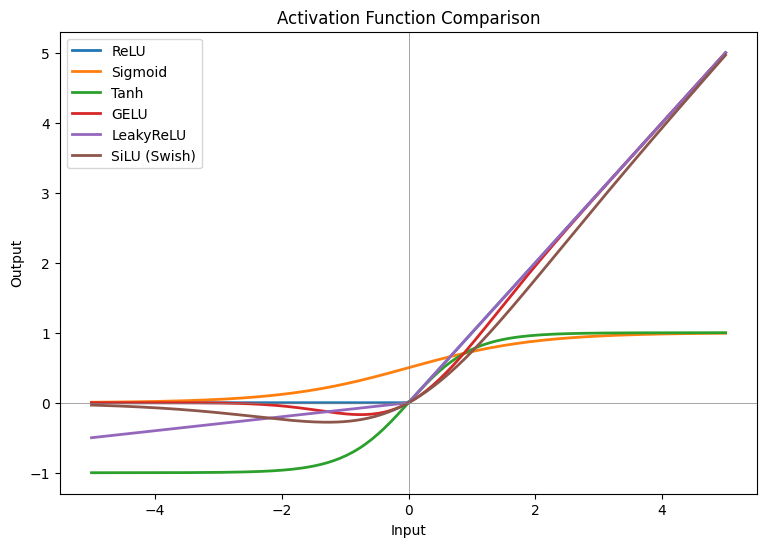

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

x = torch.linspace(-5, 5, 200)

activations = {
    "ReLU": nn.ReLU(),
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "GELU": nn.GELU(),
    "LeakyReLU": nn.LeakyReLU(negative_slope=0.1),
    "SiLU (Swish)": nn.SiLU(),
}

fig, ax = plt.subplots(figsize=(9, 6))
for name, fn in activations.items():
    ax.plot(x.numpy(), fn(x).detach().numpy(), label=name, linewidth=2)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.legend()
ax.set_title("Activation Function Comparison")
ax.set_xlabel("Input")
ax.set_ylabel("Output")
plt.show()


### Mathematical Behavior and Gradient Behavior, Per Function

| Function | Formula | Output range | Gradient behavior | Where used |
|---|---|---|---|---|
| **ReLU** | `max(0, x)` | `[0, ∞)` | Exactly 0 for `x<0` ("dead ReLU" risk), exactly 1 for `x>0` — no saturation on the positive side | Default choice for CNN hidden layers, general-purpose |
| **Sigmoid** | `1/(1+e^-x)` | `(0, 1)` | **Saturates** (gradient → 0) for large \|x\| — the classic vanishing-gradient culprit | Final layer for binary classification probability output (used WITH `BCEWithLogitsLoss`'s internal sigmoid, Chapter 19 — rarely as a hidden-layer activation anymore) |
| **Tanh** | `(e^x - e^-x)/(e^x + e^-x)` | `(-1, 1)` | Also saturates, though less severely than sigmoid (steeper near 0) | Historically common in RNNs (Chapter 44); largely superseded by ReLU/GELU elsewhere |
| **GELU** | Smooth approximation of `x * Φ(x)` (Φ = Gaussian CDF) | Roughly `(-0.17, ∞)` | Smooth everywhere, no exact "dead" zone like ReLU | The standard choice in modern Transformers (BERT, GPT) |
| **LeakyReLU** | `x if x>0 else negative_slope*x` | `(-∞, ∞)` | Small but NON-zero gradient for `x<0` — directly fixes ReLU's "dead neuron" problem | An alternative to plain ReLU when dead neurons are a concern |
| **SiLU/Swish** | `x * sigmoid(x)` | Roughly `(-0.28, ∞)` | Smooth, non-monotonic | Used in some modern CNN architectures (EfficientNet) and as GELU's close cousin |

## 3. The "Dead ReLU" Problem, Demonstrated


In [ ]:
relu = nn.ReLU()

x_negative = torch.tensor([-2.0, -1.0, -0.5], requires_grad=True)
y = relu(x_negative)
y.sum().backward()

print("Input:", x_negative.detach())
print("Output:", y.detach(), " (all zeroed -- ReLU outputs exactly 0 for any negative input)")
print("Gradient:", x_negative.grad, " (ALSO exactly zero -- NO learning signal flows back through a 'dead' ReLU)")
print("\nIf a neuron's weights end up such that its input is ALWAYS negative across your entire")
print("dataset, that neuron's gradient is PERMANENTLY zero -- it can never recover or update again.")
print("This is the 'dead ReLU' problem, and it's exactly what LeakyReLU/GELU's non-zero")
print("negative-region gradient is designed to prevent.")


Input: tensor([-2.0000, -1.0000, -0.5000])
Output: tensor([0., 0., 0.])  (all zeroed -- ReLU outputs exactly 0 for any negative input)
Gradient: tensor([0., 0., 0.])  (ALSO exactly zero -- NO learning signal flows back through a 'dead' ReLU)

If a neuron's weights end up such that its input is ALWAYS negative across your entire
dataset, that neuron's gradient is PERMANENTLY zero -- it can never recover or update again.
This is the 'dead ReLU' problem, and it's exactly what LeakyReLU/GELU's non-zero
negative-region gradient is designed to prevent.


### Common Mistakes
- Using Sigmoid/Tanh as a **hidden**-layer activation in a deep network — invites vanishing gradients (Chapter 14) far more than ReLU/GELU-family activations do; reserve Sigmoid specifically for a final binary-classification output layer (and even there, prefer using it fused inside `BCEWithLogitsLoss`, Chapter 19, for numerical stability).
- Not recognizing "dead ReLU" as a specific, diagnosable training pathology (many neurons outputting exactly zero, with exactly zero gradient, permanently) — a genuine debugging target (Chapter 32's training diagnostics).
- Applying an activation function to a model's **final** output when using a loss function (like `CrossEntropyLoss`) that expects **raw logits**, not probabilities — a very common, specific mistake fully covered in Chapter 19.

### Interview Insight
**Q: What is the "dead ReLU" problem, and what are two ways to address it?**
A: ReLU outputs exactly zero (and has exactly zero gradient) for any negative input — if a neuron's weights evolve such that its pre-activation input is negative for essentially every sample in the training data, that neuron's gradient becomes permanently zero, meaning it can never update or recover ("dies") for the rest of training, effectively wasting that neuron's capacity. Two standard fixes: `LeakyReLU` (or `PReLU`), which allows a small non-zero gradient for negative inputs instead of exactly zero, giving a dead neuron a path back to usefulness; and careful weight initialization (Chapter 30, e.g., Kaiming/He initialization) specifically designed to keep ReLU networks' activations in a healthy range from the start, reducing how often neurons die in the first place.

### Exercise
1. Plot ReLU, LeakyReLU, and GELU on the same axes over `[-5, 5]` and visually compare their behavior near zero.
2. Create a tensor of all-negative values, pass it through ReLU, and confirm both the output and the gradient are exactly zero — then repeat with LeakyReLU and confirm the gradient is non-zero.

### Quiz (Chapter 18)
1. Why is non-linearity between layers mathematically necessary for depth to matter at all?
2. Why does Sigmoid's saturation cause vanishing gradients specifically for large \|x\|?
3. What specifically causes the "dead ReLU" problem, and name two fixes?
4. Why is GELU the standard choice in modern Transformers rather than plain ReLU?


---
# CHAPTER 19 — LOSS FUNCTIONS

## 1. Concept
The loss function is what training actually optimizes — it converts a model's predictions and the true targets into a single scalar number that `.backward()` can differentiate. Getting the loss function's exact **input format expectations** right (logits vs. probabilities, target shape/dtype) is one of the most common sources of PyTorch errors (Chapter 33).

## 2. `nn.CrossEntropyLoss` — the Standard Multi-Class Classification Loss


In [ ]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

# Model outputs RAW LOGITS -- NOT probabilities, and CrossEntropyLoss expects EXACTLY this
logits = torch.tensor([[2.0, 1.0, 0.1], [0.5, 2.5, 0.3]])   # (batch=2, num_classes=3)
targets = torch.tensor([0, 1])   # INTEGER class indices, dtype MUST be int64/long -- NOT one-hot!

loss = criterion(logits, targets)
print("Loss:", loss.item())

# A CRITICAL, extremely common mistake: applying softmax BEFORE CrossEntropyLoss
softmaxed = torch.softmax(logits, dim=1)
try:
    wrong_loss = criterion(softmaxed, targets)
    print("\n'Works' without error, but is MATHEMATICALLY WRONG:", wrong_loss.item(), "!= ", loss.item())
except Exception as e:
    print(e)


Loss: 0.31853973865509033

'Works' without error, but is MATHEMATICALLY WRONG: 0.745010256767273 !=  0.31853973865509033


### Why Applying Softmax Before `CrossEntropyLoss` Is a Serious, Silent Bug
`nn.CrossEntropyLoss` **internally combines** a log-softmax operation AND negative-log-likelihood loss into one numerically-stable computation — it expects **raw, unnormalized logits** as input, not pre-softmaxed probabilities. Applying softmax yourself before passing to `CrossEntropyLoss` **does not raise an error** (both a raw logit and a softmax output are valid-shaped float tensors) — it silently applies softmax **twice**, producing an incorrect loss value and, worse, incorrect gradients, subtly degrading training without any obvious symptom. This is one of the single most common, most damaging PyTorch mistakes — genuinely worth memorizing: **model outputs → raw logits → straight into `CrossEntropyLoss`, no activation in between.**

## 3. `nn.BCEWithLogitsLoss` vs. `Sigmoid` + `nn.BCELoss` — the Same Pattern for Binary Classification


In [ ]:
bce_with_logits = nn.BCEWithLogitsLoss()
bce_plain = nn.BCELoss()

logits_binary = torch.tensor([2.0, -1.5, 0.3])           # raw logits
targets_binary = torch.tensor([1.0, 0.0, 1.0])            # targets are FLOATS (0.0/1.0), not ints, for binary loss

# CORRECT: raw logits directly into BCEWithLogitsLoss
loss_correct = bce_with_logits(logits_binary, targets_binary)
print("BCEWithLogitsLoss (raw logits, correct):", loss_correct.item())

# EQUIVALENT but LESS NUMERICALLY STABLE: manual sigmoid + BCELoss
probs = torch.sigmoid(logits_binary)
loss_manual = bce_plain(probs, targets_binary)
print("Sigmoid + BCELoss (manual, less stable):", loss_manual.item())
print("\nBoth are MATHEMATICALLY equivalent and give nearly the same VALUE here, but")
print("BCEWithLogitsLoss is preferred because it fuses sigmoid + BCE into one numerically")
print("stable computation (avoiding potential log(0) issues from an extremely confident,")
print("saturated sigmoid output) -- ALWAYS prefer the WithLogits version in real code.")


BCEWithLogitsLoss (raw logits, correct): 0.29423215985298157
Sigmoid + BCELoss (manual, less stable): 0.29423221945762634

Both are MATHEMATICALLY equivalent and give nearly the same VALUE here, but
BCEWithLogitsLoss is preferred because it fuses sigmoid + BCE into one numerically
stable computation (avoiding potential log(0) issues from an extremely confident,
saturated sigmoid output) -- ALWAYS prefer the WithLogits version in real code.


### Parameter / Shape Reference Table

| Loss | Input expects | Target expects | Target dtype |
|---|---|---|---|
| `nn.CrossEntropyLoss` | Raw logits `(batch, num_classes)` | Class indices `(batch,)` | `int64` (long) |
| `nn.NLLLoss` | **Log-probabilities** `(batch, num_classes)` (i.e., you apply `log_softmax` yourself first) | Class indices `(batch,)` | `int64` |
| `nn.BCEWithLogitsLoss` | Raw logits `(batch,)` or `(batch, 1)` | Binary labels, same shape | `float32` |
| `nn.BCELoss` | Probabilities (0-1, post-sigmoid) | Binary labels, same shape | `float32` |
| `nn.MSELoss` | Raw predictions, any shape | Same shape as predictions | `float32` |
| `nn.L1Loss` | Raw predictions, any shape | Same shape as predictions | `float32` |

**`CrossEntropyLoss` vs `NLLLoss`**: `CrossEntropyLoss` is literally `log_softmax` + `NLLLoss` fused into one call — mathematically, `CrossEntropyLoss(logits, targets) == NLLLoss(log_softmax(logits), targets)`. Use `CrossEntropyLoss` directly on raw logits in the overwhelming majority of cases; `NLLLoss` is used directly only when you specifically need access to the intermediate log-probabilities for some other purpose.

### Common Mistakes
- Applying `softmax`/`sigmoid` before `CrossEntropyLoss`/`BCEWithLogitsLoss` — the single most common loss-function mistake in this entire course, silently producing wrong (but not error-raising) results.
- Passing float targets to `CrossEntropyLoss` (which requires `int64` class indices) or one-hot-encoded targets instead of plain class indices — raises a clear dtype/shape error, at least.
- Using `nn.BCELoss` with raw logits instead of post-sigmoid probabilities — mathematically wrong, and can produce `NaN` from `log(negative number)` internally for genuinely out-of-range "probability" inputs.
- Mismatched target shape for `MSELoss`/regression losses — e.g., predictions shaped `(batch, 1)` against targets shaped `(batch,)` silently **broadcasts** (Chapter 8) into an unintended, much larger result via an implicit outer-product-like broadcast, rather than raising an error — a genuinely dangerous silent shape bug.

### Interview Insight
**Q: Why does `nn.CrossEntropyLoss` expect raw logits rather than softmax probabilities, and what happens if you pass softmax output anyway?**
A: `CrossEntropyLoss` internally fuses a `log_softmax` operation with negative log-likelihood loss into a single, numerically stable computation — this fusion specifically avoids numerical issues that can arise from computing softmax and then taking its log as two separate steps (very small softmax outputs can lose precision before the subsequent log). If you apply softmax yourself first and then pass that into `CrossEntropyLoss`, it internally applies `log_softmax` to your *already-softmaxed* output — effectively applying softmax twice — which does not raise an error (the input is still a valid-shaped tensor) but produces a mathematically incorrect loss value and incorrect gradients, silently degrading training in a way that's easy to miss without specifically checking for it.

### Exercise
1. Compute `CrossEntropyLoss` on a `(3, 5)` logits tensor with class-index targets, and verify the loss decreases if you construct logits that "obviously" match the targets (large value at the correct index) versus logits that don't.
2. Manually verify `CrossEntropyLoss(logits, targets)` equals `NLLLoss(log_softmax(logits, dim=1), targets)` using `torch.allclose()`.

### Quiz (Chapter 19)
1. What does `CrossEntropyLoss` expect as input — logits or probabilities — and why does passing the wrong one not raise an error?
2. What dtype must `CrossEntropyLoss`'s targets be, and what format (indices vs. one-hot)?
3. Why is `BCEWithLogitsLoss` preferred over manual `Sigmoid` + `BCELoss`?
4. What's the mathematical relationship between `CrossEntropyLoss` and `NLLLoss`?


---
# CHAPTER 20 — OPTIMIZERS

## 1. Concept
An optimizer implements the **parameter update rule** — given each parameter's gradient (computed by `.backward()`, Chapter 13), how exactly should that parameter's value change? All optimizers share the same basic goal (move parameters to reduce the loss) but differ in *how* they use gradient history and per-parameter adaptivity to get there faster/more reliably.

## 2. `torch.optim.SGD` — the Foundational Algorithm


In [ ]:
import torch
import torch.nn as nn

model = nn.Linear(10, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

x = torch.randn(32, 10)
target = torch.randn(32, 1)
criterion = nn.MSELoss()

# ONE training step, showing the canonical 3-call pattern
optimizer.zero_grad()               # Chapter 15's lesson -- clear old gradients first
prediction = model(x)
loss = criterion(prediction, target)
loss.backward()                     # compute new gradients
optimizer.step()                    # APPLY the update: param = param - lr * gradient  (+ momentum term)

print("Loss after one step:", loss.item())
print("\nSGD's basic update rule: param -= lr * param.grad")
print("With momentum, it additionally accumulates a running 'velocity' from past gradients,")
print("helping push through small local bumps/noise and accelerating consistent directions.")


Loss after one step: 1.5515002012252808

SGD's basic update rule: param -= lr * param.grad
With momentum, it additionally accumulates a running 'velocity' from past gradients,
helping push through small local bumps/noise and accelerating consistent directions.


### Parameter Explanation
- `lr` (learning rate) — the single most important hyperparameter in all of deep learning; too large causes unstable/diverging training (loss oscillates or explodes), too small causes painfully slow convergence.
- `momentum` — accumulates a weighted running average of past gradients, adding a "velocity" term to the update — helps the optimizer maintain progress through noisy or locally-flat gradient regions, and is standard practice with plain SGD (rarely used without it).

## 3. `torch.optim.Adam` and `AdamW` — Adaptive, Per-Parameter Learning Rates


In [ ]:
adam_optimizer = torch.optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.999))
adamw_optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

print("Adam maintains, PER PARAMETER, a running estimate of:")
print("  1. the gradient's mean (first moment, controlled by beta1=0.9)")
print("  2. the gradient's SQUARED magnitude (second moment, controlled by beta2=0.999)")
print("and uses these to ADAPTIVELY scale each parameter's individual learning rate --")
print("parameters with consistently large gradients get smaller effective steps,")
print("parameters with small/sparse gradients get relatively LARGER effective steps.")


Adam maintains, PER PARAMETER, a running estimate of:
  1. the gradient's mean (first moment, controlled by beta1=0.9)
  2. the gradient's SQUARED magnitude (second moment, controlled by beta2=0.999)
and uses these to ADAPTIVELY scale each parameter's individual learning rate --
parameters with consistently large gradients get smaller effective steps,
parameters with small/sparse gradients get relatively LARGER effective steps.


### `Adam` vs. `AdamW` — the Weight Decay Distinction, Precisely
This is a genuinely important, often-misunderstood detail. **Weight decay** (a regularization technique — Chapter 31 — that shrinks parameters toward zero to reduce overfitting) can be implemented two mathematically **different** ways:
1. **L2 regularization added to the loss/gradient** — the traditional approach, and what plain `Adam`'s `weight_decay` parameter actually does. Because of how Adam's adaptive per-parameter scaling interacts with this gradient-based approach, the *effective* amount of regularization ends up inconsistent across parameters in a way that's not quite what was intended.
2. **Decoupled weight decay** — directly shrinking each parameter's value by a fixed factor, entirely **separate** from the gradient-based update — this is what `AdamW`'s `weight_decay` does, and it was specifically introduced (in a well-known 2017 paper) because it fixes Adam's inconsistent-regularization issue.

**Practical guidance**: use `AdamW` over plain `Adam` whenever weight decay is being used (which is most of the time) — `AdamW` is now the standard default optimizer for training Transformers and most modern architectures.

## 4. Comparing SGD vs. Adam vs. AdamW — When Industry Engineers Choose Each


In [ ]:
comparison = """
| Optimizer | Convergence speed | Generalization | Typical use |
|-----------|-------------------|-----------------|-------------|
| SGD (+momentum) | Slower, needs careful LR tuning | Often BETTER final generalization for CNNs, given enough tuning/training time | Classic computer vision (ResNet-style training), when squeezing out the best final accuracy matters more than fast iteration |
| Adam | Fast, robust to LR choice, adapts per-parameter | Can sometimes generalize slightly worse than well-tuned SGD | Fast prototyping, NLP tasks, most non-CV research |
| AdamW | Same speed/robustness as Adam | FIXES Adam's weight-decay-related generalization gap | The modern DEFAULT for Transformers, LLMs, and most current architectures |
"""
print(comparison)
print("A common, pragmatic industry pattern: use AdamW for FAST initial development and")
print("hyperparameter search, then (for CV models specifically, where final squeezed-out")
print("accuracy matters most) consider a well-tuned SGD+momentum run for the FINAL production model.")



| Optimizer | Convergence speed | Generalization | Typical use |
|-----------|-------------------|-----------------|-------------|
| SGD (+momentum) | Slower, needs careful LR tuning | Often BETTER final generalization for CNNs, given enough tuning/training time | Classic computer vision (ResNet-style training), when squeezing out the best final accuracy matters more than fast iteration |
| Adam | Fast, robust to LR choice, adapts per-parameter | Can sometimes generalize slightly worse than well-tuned SGD | Fast prototyping, NLP tasks, most non-CV research |
| AdamW | Same speed/robustness as Adam | FIXES Adam's weight-decay-related generalization gap | The modern DEFAULT for Transformers, LLMs, and most current architectures |

A common, pragmatic industry pattern: use AdamW for FAST initial development and
hyperparameter search, then (for CV models specifically, where final squeezed-out
accuracy matters most) consider a well-tuned SGD+momentum run for the FINAL production model.


### Common Mistakes
- Using plain `Adam` with `weight_decay` set, unaware `AdamW` handles this more correctly — a genuinely common, easy-to-miss suboptimal default in real codebases (including some older tutorials/papers).
- Choosing a learning rate by guessing rather than following established starting points (`1e-3` is a common reasonable Adam/AdamW starting point; SGD often needs a notably higher LR like `1e-2` or `1e-1` combined with a scheduler, Chapter 21) — a poorly-chosen LR is one of the most common causes of "my model won't train" (Chapter 33).
- Forgetting `optimizer.zero_grad()` before `loss.backward()` — reintroducing Chapter 15's gradient-accumulation bug, now in the full training-step context.
- Passing the wrong set of parameters to the optimizer (e.g., a stale reference to a model's old parameters after reconstructing the model) — the optimizer will silently update tensors that are no longer actually part of the live model's forward pass.

### Interview Insight
**Q: What's the actual difference between `Adam`'s `weight_decay` parameter and `AdamW`'s, given they're both called "weight_decay"?**
A: Plain `Adam` implements weight decay as L2 regularization added directly to the gradient before Adam's adaptive per-parameter scaling is applied — because that scaling divides by an estimate of each parameter's gradient magnitude, the *effective* regularization strength ends up inconsistently applied across parameters with different gradient magnitudes, which isn't the intended, uniform shrinkage weight decay is meant to provide. `AdamW` implements **decoupled** weight decay — it shrinks each parameter directly by a fixed proportional amount, entirely separately from the adaptive gradient-based update — restoring the consistent, uniform regularization effect weight decay is meant to have. This is why `AdamW` has become the standard modern default whenever weight decay is used, which is most of the time in current architectures.

### Exercise
1. Train a simple linear model for 20 manual steps using plain SGD (no momentum), then repeat with SGD+momentum=0.9, and compare how quickly the loss decreases.
2. Write out, from memory, the canonical 5-line training-step pattern (`zero_grad`, forward, loss, `backward`, `step`).

### Quiz (Chapter 20)
1. What does Adam adaptively adjust, per-parameter, that plain SGD does not?
2. What's the precise mathematical difference between Adam's and AdamW's weight decay implementation?
3. Why is AdamW now the standard default for Transformer training?
4. What's a common, reasonable starting learning rate for Adam/AdamW, and why does SGD typically need a different one?

### Chapter 20 Summary
- The canonical training step: `optimizer.zero_grad()` → forward pass → compute loss → `loss.backward()` → `optimizer.step()`.
- SGD+momentum remains competitive for final CV model accuracy with enough tuning; Adam/AdamW are faster, more robust defaults, with AdamW's decoupled weight decay making it the modern standard, especially for Transformers.

---

## END OF NOTEBOOK 4 — What You Should Now Be Able To Do
- Build any `nn.Module` subclass correctly (with `super().__init__()`, registered submodules, `forward()`), and explain parameter vs. buffer registration.
- Use `nn.Linear`, `nn.Conv2d` (preview), `nn.Dropout`, `nn.BatchNorm1d`/`nn.LayerNorm` correctly, and explain each one's train/eval-mode-dependent behavior.
- Choose activation functions deliberately, explain the dead-ReLU problem, and recognize saturating activations as a vanishing-gradient risk.
- Use `CrossEntropyLoss` and `BCEWithLogitsLoss` correctly with raw logits (never pre-softmaxed/pre-sigmoided input) — the single most consequential lesson in this notebook.
- Write the canonical training step correctly with `zero_grad`/`backward`/`step`, and choose between SGD, Adam, and AdamW deliberately.

## Before Moving to Notebook 5 (Chapters 21–25: Learning Rate Schedulers, First Neural Network, Professional Training Loop, Dataset and DataLoader, Custom Datasets)
 